In [1]:
import pandas as pd # main library we are using for tabular data ---> later becomes a Pandas dataframe
import numpy as np # NumPy is used for numerical operations and arrays later.
import matplotlib.pyplot as plt # Matplotlib is our basic plotting library.
import seaborn as sns # Seaborn is a plotting library built on top of Matplotlib.
from pathlib import Path # Path is Python's cleaner way of working with files and directories.

pd.set_option("display.max_columns", 30) # only affects display, but even here, not really
sns.set_theme() # applies seaborn's default visual styling to plots

In [2]:
print(list(Path("../data").rglob("*.csv"))) # go up one directory and recursive glob to list all csv files

[PosixPath('../data/SkillCraft1_Dataset.csv'), PosixPath('../data/dota2Test.csv'), PosixPath('../data/dota2Train.csv')]


In [3]:
# Actually load and inspect SkillCraft
df = pd.read_csv("../data/SkillCraft1_Dataset.csv") # ---> converts it into a Pandas DataFrame
print("Shape (rows, columns):", df.shape) # Number of rows and columns
df.head() # displays the first five rows by default.

Shape (rows, columns): (3395, 20)


,GameID,LeagueIndex,Age,HoursPerWeek,TotalHours,APM,SelectByHotkeys,AssignToHotkeys,UniqueHotkeys,MinimapAttacks,MinimapRightClicks,NumberOfPACs,GapBetweenPACs,ActionLatency,ActionsInPAC,TotalMapExplored,WorkersMade,UniqueUnitsMade,ComplexUnitsMade,ComplexAbilitiesUsed
0,52,5,27,10,3000,143.7180,0.003515,0.000220,7,0.000110,0.000392,0.004849,32.6677,40.8673,4.7508,28,0.001397,6,0.0,0.000000
1,55,5,23,10,5000,129.2322,0.003304,0.000259,4,0.000294,0.000432,0.004307,32.9194,42.3454,4.8434,22,0.001193,5,0.0,0.000208
2,56,4,30,10,200,69.9612,0.001101,0.000336,4,0.000294,0.000461,0.002926,44.6475,75.3548,4.0430,22,0.000745,6,0.0,0.000189
3,57,3,19,20,400,107.6016,0.001034,0.000213,1,0.000053,0.000543,0.003783,29.2203,53.7352,4.9155,19,0.000426,7,0.0,0.000384
4,58,3,32,10,500,122.8908,0.001136,0.000327,2,0.000000,0.001329,0.002368,22.6885,62.0813,9.3740,15,0.001174,4,0.0,0.000019


In [4]:
df.dtypes # 3 kinds of data types are listed below --> integer, object, and float. Why float?! Need to inspect

GameID                    int64
LeagueIndex               int64
Age                      object
HoursPerWeek             object
TotalHours               object
APM                     float64
SelectByHotkeys         float64
AssignToHotkeys         float64
UniqueHotkeys             int64
MinimapAttacks          float64
MinimapRightClicks      float64
NumberOfPACs            float64
GapBetweenPACs          float64
ActionLatency           float64
ActionsInPAC            float64
TotalMapExplored          int64
WorkersMade             float64
UniqueUnitsMade           int64
ComplexUnitsMade        float64
ComplexAbilitiesUsed    float64
dtype: object

In [5]:
# Inspect the most common values in the three columns that were read as objects.
# This helps determine whether they are mostly numeric and whether unusual values may be present.
for col in ["Age", "HoursPerWeek", "TotalHours"]:
    print(col) # print column name
    print(df[col].value_counts().head(8))
    print()

Age
Age
20    357
21    344
18    325
22    314
19    313
23    259
16    256
17    248
Name: count, dtype: int64

HoursPerWeek
HoursPerWeek
10    411
8     390
20    335
12    331
6     323
28    280
24    233
16    223
Name: count, dtype: int64

TotalHours
TotalHours
500     328
400     213
1000    210
300     202
600     187
800     186
700     170
200     168
Name: count, dtype: int64



In [6]:
# Attempt to convert the suspicious columns to numeric values.
# Any value that cannot be converted is coerced to NaN so we can identify it.

for col in ["Age", "HoursPerWeek", "TotalHours"]:
    converted = pd.to_numeric(df[col], errors="coerce")
    bad = df[col][converted.isna()]
    print(col, "| non-numeric count:", len(bad), "| values:", bad.unique())

Age | non-numeric count: 55 | values: ['?']
HoursPerWeek | non-numeric count: 56 | values: ['?']
TotalHours | non-numeric count: 57 | values: ['?']


In [7]:
# Work on a temporary copy so the original DataFrame is not modified during investigation.
tmp = df.copy()

# Convert the three columns to numeric, replacing '?' with NaN.
for col in ["Age", "HoursPerWeek", "TotalHours"]:
    tmp[col] = pd.to_numeric(tmp[col], errors="coerce")

# Identify rows with at least one missing value across the three columns.
missing_rows = tmp[tmp[["Age", "HoursPerWeek", "TotalHours"]].isna().any(axis=1)]

# Check how many rows are affected and which skill leagues they belong to.
print("Rows with any missing value:", len(missing_rows))
print()
print("Rows with missing values, by league:")
print(missing_rows["LeagueIndex"].value_counts().sort_index())
print()
print("All rows, by league:")
print(tmp["LeagueIndex"].value_counts().sort_index())

Rows with any missing value: 57

Rows with missing values, by league:
LeagueIndex
5     2
8    55
Name: count, dtype: int64

All rows, by league:
LeagueIndex
1    167
2    347
3    553
4    811
5    806
6    621
7     35
8     55
Name: count, dtype: int64


In [8]:
df = pd.read_csv("../data/SkillCraft1_Dataset.csv", na_values="?")
print(df.isna().sum()[lambda s: s > 0]) 
# filters the result to show only columns where the number of missing values is greater than zero.
print()
print(df[["Age", "HoursPerWeek", "TotalHours"]].dtypes)

Age             55
HoursPerWeek    56
TotalHours      57
dtype: int64

Age             float64
HoursPerWeek    float64
TotalHours      float64
dtype: object


In [9]:
# just stores the three problematic column names in a list.
cols = ["Age", "HoursPerWeek", "TotalHours"]
n_missing = df[cols].isna().sum(axis=1) # turns every value into True or False depending on whether it is missing.
print(pd.crosstab(df["LeagueIndex"], n_missing))

col_0          0  1  2   3
LeagueIndex               
1            167  0  0   0
2            347  0  0   0
3            553  0  0   0
4            811  0  0   0
5            804  1  1   0
6            621  0  0   0
7             35  0  0   0
8              0  0  0  55


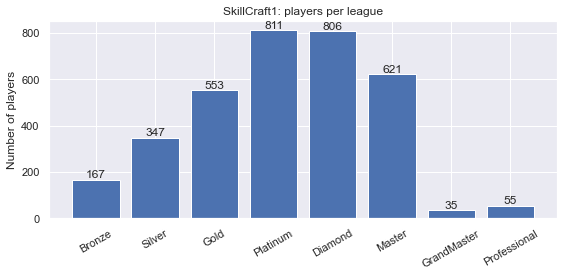

In [10]:
# Create the figures folder if it does not already exist.
Path("../figures").mkdir(exist_ok=True)

# Map numeric league labels to readable skill names.
league_names = {1: "Bronze", 2: "Silver", 3: "Gold", 4: "Platinum",
                5: "Diamond", 6: "Master", 7: "GrandMaster", 8: "Professional"}

# Count the number of players in each skill league.
counts = df["LeagueIndex"].value_counts().sort_index()

# Visualise class distribution to check whether the target is balanced.
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar([league_names[i] for i in counts.index], counts.values)
ax.bar_label(bars)
ax.set_ylabel("Number of players")
ax.set_title("SkillCraft1: players per league")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig("../figures/skillcraft_league_distribution.png", dpi=150)
plt.show()

In [11]:
# Exclude the identifier and the three variables containing problematic missing values.
drop_cols = ["GameID", "Age", "HoursPerWeek", "TotalHours"]

# X contains the 15 clean gameplay features; y contains the skill-class target.
X = df.drop(columns=drop_cols + ["LeagueIndex"]) # gameplay behavior
y = df["LeagueIndex"]                            # skill league

# Confirm the final feature/target dimensions and verify that X has no missing values.
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Missing values left in X:", X.isna().sum().sum())
print(X.columns.tolist())

X shape: (3395, 15)
y shape: (3395,)
Missing values left in X: 0
['APM', 'SelectByHotkeys', 'AssignToHotkeys', 'UniqueHotkeys', 'MinimapAttacks', 'MinimapRightClicks', 'NumberOfPACs', 'GapBetweenPACs', 'ActionLatency', 'ActionsInPAC', 'TotalMapExplored', 'WorkersMade', 'UniqueUnitsMade', 'ComplexUnitsMade', 'ComplexAbilitiesUsed']


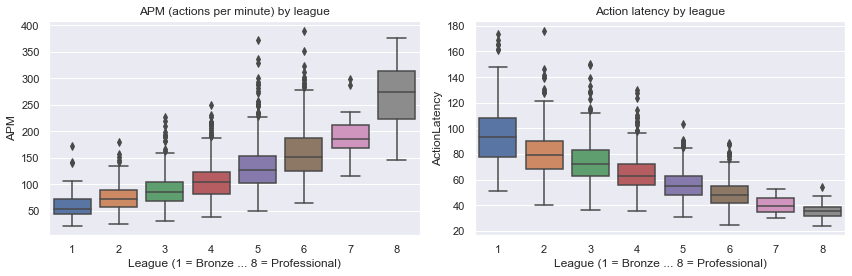

In [12]:
# Compare two key gameplay-behaviour features across skill leagues.
# Boxplots show the distribution, median and spread of APM and ActionLatency
# for each league.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=df, x="LeagueIndex", y="APM", ax=axes[0])
axes[0].set_title("APM (actions per minute) by league")
sns.boxplot(data=df, x="LeagueIndex", y="ActionLatency", ax=axes[1])
axes[1].set_title("Action latency by league")
for ax in axes:
    ax.set_xlabel("League (1 = Bronze ... 8 = Professional)")
plt.tight_layout()
plt.savefig("../figures/skillcraft_apm_latency_by_league.png", dpi=150)
plt.show()

In [13]:
df.groupby("LeagueIndex")[["APM", "ActionLatency"]].median().round(2)

,APM,ActionLatency
LeagueIndex,,
1,54.04,93.33
2,71.68,79.24
3,85.96,72.10
4,103.81,62.77
5,126.01,54.99
6,152.19,47.96
7,185.34,39.73
8,274.34,35.41


In [14]:
# Generate descriptive statistics for all 15 gameplay features.
# This helps inspect their ranges, central tendency and variability.
X.describe().T.round(4)

,count,mean,std,min,25%,50%,75%,max
APM,3395.0,117.0469,51.9453,22.0596,79.9002,108.0102,142.7904,389.8314
SelectByHotkeys,3395.0,0.0043,0.0053,0.0000,0.0013,0.0025,0.0051,0.0431
AssignToHotkeys,3395.0,0.0004,0.0002,0.0000,0.0002,0.0004,0.0005,0.0018
UniqueHotkeys,3395.0,4.3647,2.3603,0.0000,3.0000,4.0000,6.0000,10.0000
MinimapAttacks,3395.0,0.0001,0.0002,0.0000,0.0000,0.0000,0.0001,0.0030
MinimapRightClicks,3395.0,0.0004,0.0004,0.0000,0.0001,0.0003,0.0005,0.0040
NumberOfPACs,3395.0,0.0035,0.0010,0.0007,0.0028,0.0034,0.0040,0.0080
GapBetweenPACs,3395.0,40.3616,17.1536,6.6667,28.9578,36.7235,48.2905,237.1429
ActionLatency,3395.0,63.7394,19.2389,24.0936,50.4466,60.9318,73.6813,176.3721
ActionsInPAC,3395.0,5.2730,1.4948,2.0389,4.2728,5.0955,6.0336,18.5581


In [15]:
corr_with_league = df.drop(columns=["GameID", "Age", "HoursPerWeek", "TotalHours"]).corr()["LeagueIndex"].drop("LeagueIndex")
corr_with_league.sort_values(key=abs, ascending=False).round(3)

ActionLatency          -0.674
APM                     0.662
NumberOfPACs            0.612
GapBetweenPACs         -0.553
AssignToHotkeys         0.531
SelectByHotkeys         0.491
UniqueHotkeys           0.351
MinimapAttacks          0.313
WorkersMade             0.296
MinimapRightClicks      0.233
TotalMapExplored        0.221
ComplexUnitsMade        0.149
ComplexAbilitiesUsed    0.146
ActionsInPAC            0.143
UniqueUnitsMade         0.134
Name: LeagueIndex, dtype: float64

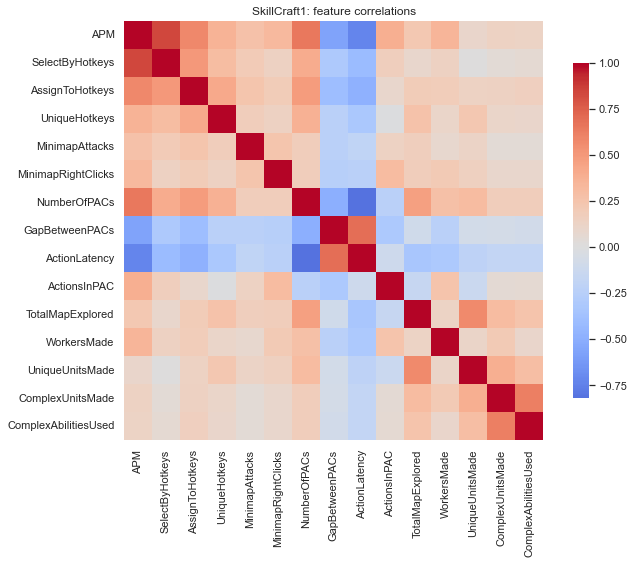

In [16]:
plt.figure(figsize=(10, 8))
corr = X.corr()
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("SkillCraft1: feature correlations")
plt.tight_layout()
plt.savefig("../figures/skillcraft_correlation_heatmap.png", dpi=150)
plt.show()